In [ ]:
# ==========================================================
# RESET NOTEBOOK 6
# ==========================================================

import os
import shutil
import pandas as pd

BASE_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset"

MASTER_FILE = os.path.join(
    BASE_FOLDER,
    "08_Master_Pipeline",
    "Master_Pipeline.csv"
)

FEATURE_FOLDER = os.path.join(
    BASE_FOLDER,
    "09_Transit_Features"
)

LOG_FOLDER = os.path.join(
    BASE_FOLDER,
    "11_Logs"
)

FEATURE_FILE = os.path.join(
    FEATURE_FOLDER,
    "Transit_Features.csv"
)

LOG_FILE = os.path.join(
    LOG_FOLDER,
    "Transit_Log.csv"
)

print("="*60)
print("RESETTING NOTEBOOK 6")
print("="*60)

# ----------------------------------------------------------
# Remove Notebook 6 columns from Master Pipeline
# ----------------------------------------------------------

master = pd.read_csv(MASTER_FILE)

columns_to_remove = [

    "depth_ppm",

    "T_tot_hours",

    "T_in_hours",

    "duration_phase",

    "ingress_phase",

    "red_chi2",

    "rms_resid"

]

existing = [

    col

    for col in columns_to_remove

    if col in master.columns

]

if existing:

    master.drop(
        columns=existing,
        inplace=True
    )

    master.to_csv(
        MASTER_FILE,
        index=False
    )

    print(f"Removed columns: {existing}")

else:

    print("No Notebook 6 columns found.")

# ----------------------------------------------------------
# Delete Transit Feature Folder
# ----------------------------------------------------------

if os.path.exists(FEATURE_FOLDER):

    shutil.rmtree(FEATURE_FOLDER)

os.makedirs(
    FEATURE_FOLDER,
    exist_ok=True
)

print("Transit feature folder reset.")

# ----------------------------------------------------------
# Delete Log Folder
# ----------------------------------------------------------

if os.path.exists(LOG_FOLDER):

    shutil.rmtree(LOG_FOLDER)

os.makedirs(
    LOG_FOLDER,
    exist_ok=True
)

print("Log folder reset.")

print()
print("="*60)
print("RESET COMPLETE")
print("="*60)

print()

print("Master Columns:")

print(pd.read_csv(MASTER_FILE).columns.tolist())

RESETTING NOTEBOOK 6
No Notebook 6 columns found.
Transit feature folder reset.
Log folder reset.

RESET COMPLETE

Master Columns:
['TIC_ID', 'Label', 'Number_of_Sectors', 'Best_Sector', 'period_days', 'duration_days', 'epoch_days', 'bls_depth', 'bls_power', 'peak_sigma']


In [ ]:
# ==========================================================
# NOTEBOOK 6
# TRANSIT CHARACTERIZATION
# ==========================================================

import os
import csv
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import least_squares

from tqdm import tqdm

warnings.filterwarnings("ignore")

In [ ]:
# ==========================================================
# PATH CONFIGURATION
# ==========================================================

BASE_FOLDER = "/content/drive/MyDrive/Exoplanet_Dataset"

MASTER_FILE = os.path.join(
    BASE_FOLDER,
    "08_Master_Pipeline",
    "Master_Pipeline.csv"
)

LIGHTCURVE_FOLDER = os.path.join(
    BASE_FOLDER,
    "05_Preprocessed_LightCurves"
)

OUTPUT_FOLDER = os.path.join(
    BASE_FOLDER,
    "09_Transit_Features"
)

LOG_FOLDER = os.path.join(
    BASE_FOLDER,
    "11_Logs"
)

FEATURE_FILE = os.path.join(
    OUTPUT_FOLDER,
    "Transit_Features.csv"
)

LOG_FILE = os.path.join(
    LOG_FOLDER,
    "Transit_Log.csv"
)

os.makedirs(OUTPUT_FOLDER, exist_ok=True)
os.makedirs(LOG_FOLDER, exist_ok=True)

print("="*60)
print("PATHS INITIALIZED")
print("="*60)

print("Master File :", MASTER_FILE)
print("Light Curves:", LIGHTCURVE_FOLDER)
print("Output File :", FEATURE_FILE)
print("Log File    :", LOG_FILE)

PATHS INITIALIZED
Master File : /content/drive/MyDrive/Exoplanet_Dataset/08_Master_Pipeline/Master_Pipeline.csv
Light Curves: /content/drive/MyDrive/Exoplanet_Dataset/05_Preprocessed_LightCurves
Output File : /content/drive/MyDrive/Exoplanet_Dataset/09_Transit_Features/Transit_Features.csv
Log File    : /content/drive/MyDrive/Exoplanet_Dataset/11_Logs/Transit_Log.csv


In [ ]:
# ==========================================================
# CREATE OUTPUT FILES
# ==========================================================

if not os.path.exists(FEATURE_FILE):

    pd.DataFrame(columns=[

        "TIC_ID",

        "depth_ppm",

        "T_tot_hours",

        "T_in_hours",

        "duration_phase",

        "ingress_phase",

        "red_chi2",

        "rms_resid"

    ]).to_csv(

        FEATURE_FILE,

        index=False

    )

if not os.path.exists(LOG_FILE):

    pd.DataFrame(columns=[

        "TIC_ID",

        "Status",

        "Runtime_Seconds"

    ]).to_csv(

        LOG_FILE,

        index=False

    )

print("Output files ready.")

Output files ready.


In [ ]:
# ==========================================================
# RESUME SUPPORT
# ==========================================================

processed = set()

if os.path.exists(FEATURE_FILE):

    features = pd.read_csv(FEATURE_FILE)

    processed = set(

        features["TIC_ID"].astype(int)

    )

print("="*60)
print("Already Processed :", len(processed))
print("="*60)

Already Processed : 0


In [ ]:
# ==========================================================
# LOAD MASTER PIPELINE
# ==========================================================

master = pd.read_csv(MASTER_FILE)

print("="*60)
print("MASTER PIPELINE")
print("="*60)

print("Rows    :", len(master))
print("Columns :", len(master.columns))

display(master.head())

MASTER PIPELINE
Rows    : 1172
Columns : 10


,TIC_ID,Label,Number_of_Sectors,Best_Sector,period_days,duration_days,epoch_days,bls_depth,bls_power,peak_sigma
0,100100829,EB,3,69,0.942324,0.075,3182.749443,0.007126,928.753290,13.017379
1,1001477809,False Positive,4,48,7.656943,0.168,2616.800708,0.001701,30.981110,5.724197
2,100389539,Planet,2,88,4.280297,0.114,3693.099793,0.005744,2436.410323,14.040970
3,10048801,EB,2,47,3.700200,0.141,2583.045512,0.000936,1420.646948,9.640867
4,100589632,False Positive,1,87,3.946741,0.066,3665.759898,0.001609,75.715224,10.109563


In [ ]:
# ==========================================================
# PHASE FOLDING
# ==========================================================

def phase_fold(time, period, epoch):
    """
    Fold a light curve using the orbital period and transit epoch.

    Parameters
    ----------
    time : ndarray
        Observation times.
    period : float
        Orbital period (days).
    epoch : float
        Transit epoch (days).

    Returns
    -------
    ndarray
        Phase values in the range [-0.5, 0.5].
    """

    phase = ((time - epoch + 0.5 * period) % period) / period

    return phase - 0.5

In [ ]:
# ==========================================================
# TRAPEZOID TRANSIT MODEL
# ==========================================================

def trapezoid_model(phase, depth, duration, ingress):
    """
    Generate a trapezoidal transit model.
    """

    model = np.ones_like(phase)

    phase_abs = np.abs(phase)

    flat_half = duration / 2 - ingress

    # Flat Bottom
    flat = phase_abs <= flat_half
    model[flat] -= depth

    # Ingress / Egress
    edge = (phase_abs > flat_half) & (phase_abs <= duration / 2)

    model[edge] -= depth * (

        1 -

        (phase_abs[edge] - flat_half) / ingress

    )

    return model

In [ ]:
# ==========================================================
# WEIGHTED RESIDUAL FUNCTION
# ==========================================================

def residuals(parameters, phase, flux, flux_error):
    """
    Weighted residuals for least-squares optimisation.
    """

    depth, duration, ingress = parameters

    model = trapezoid_model(

        phase,

        depth,

        duration,

        ingress

    )

    return (flux - model) / flux_error

In [ ]:
# ==========================================================
# INITIAL PARAMETER ESTIMATION
# ==========================================================

def estimate_initial_parameters(
    flux,
    period_days,
    duration_days
):
    """
    Estimate initial parameters directly from the folded light curve.
    """

    baseline = np.median(flux)

    minimum = np.min(flux)

    depth_guess = baseline - minimum

    depth_guess = np.clip(

        depth_guess,

        1e-5,

        0.95

    )

    duration_phase = duration_days / period_days

    ingress_phase = duration_phase / 5

    return (

        depth_guess,

        duration_phase,

        ingress_phase

    )

In [ ]:
# ==========================================================
# TRAPEZOID FITTING
# ==========================================================

def fit_trapezoid(
    phase,
    flux,
    flux_error,
    period_days,
    duration_days
):
    """
    Fit a trapezoidal transit model to a phase-folded light curve.
    """

    # ------------------------------------------------------
    # Initial Parameter Estimates
    # ------------------------------------------------------

    depth_guess, duration_phase, ingress_phase = \
        estimate_initial_parameters(

            flux,

            period_days,

            duration_days

        )

    # ------------------------------------------------------
    # Minimum Data Requirement
    # ------------------------------------------------------

    if len(phase) < 30:

        raise ValueError(

            "Too few data points for fitting."

        )

    # ------------------------------------------------------
    # Parameter Bounds
    # ------------------------------------------------------

    lower = np.array([

        1e-6,

        duration_phase * 0.50,

        duration_phase * 0.05

    ])

    upper = np.array([

        1.00,

        duration_phase * 2.00,

        duration_phase * 0.50

    ])

    # ------------------------------------------------------
    # Initial Guess
    # ------------------------------------------------------

    x0 = np.array([

        depth_guess,

        duration_phase,

        ingress_phase

    ])

    epsilon = 1e-10

    x0 = np.clip(

        x0,

        lower + epsilon,

        upper - epsilon

    )

    # ------------------------------------------------------
    # Least Squares Optimization
    # ------------------------------------------------------

    result = least_squares(

        residuals,

        x0=x0,

        bounds=(lower, upper),

        args=(

            phase,

            flux,

            flux_error

        )

    )

    return result

In [ ]:
# ==========================================================
# TRANSIT FEATURE EXTRACTION
# ==========================================================

def extract_features(
    fit_result,
    phase,
    flux,
    flux_error,
    period_days
):
    """
    Convert fitted trapezoid parameters into
    physics-based transit features.
    """

    depth = fit_result.x[0]

    duration_phase = fit_result.x[1]

    ingress_phase = fit_result.x[2]

    # ------------------------------------------------------
    # Model
    # ------------------------------------------------------

    model_flux = trapezoid_model(

        phase,

        depth,

        duration_phase,

        ingress_phase

    )

    # ------------------------------------------------------
    # Residuals
    # ------------------------------------------------------

    residual = flux - model_flux

    red_chi2 = np.sum(

        (residual / flux_error) ** 2

    ) / (

        len(flux) - 3

    )

    rms_residual = np.sqrt(

        np.mean(

            residual ** 2

        )

    )

    # ------------------------------------------------------
    # Return Features
    # ------------------------------------------------------

    return {

        "depth_ppm":

            depth * 1e6,

        "T_tot_hours":

            duration_phase * period_days * 24,

        "T_in_hours":

            ingress_phase * period_days * 24,

        "duration_phase":

            duration_phase,

        "ingress_phase":

            ingress_phase,

        "red_chi2":

            red_chi2,

        "rms_resid":

            rms_residual,

        "model_flux":

            model_flux

    }

In [ ]:
# ==========================================================
# PROCESS A SINGLE STAR
# ==========================================================

def process_star(row):
    """
    Process a single target and extract transit features.
    """

    # ------------------------------------------------------
    # Metadata
    # ------------------------------------------------------

    tic_id = int(row["TIC_ID"])

    period_days = row["period_days"]

    duration_days = row["duration_days"]

    epoch_days = row["epoch_days"]

    best_sector = row["Best_Sector"]

    # ------------------------------------------------------
    # Load Light Curve
    # ------------------------------------------------------

    lightcurve = pd.read_csv(

        os.path.join(

            LIGHTCURVE_FOLDER,

            f"TIC_{tic_id}.csv"

        )

    )

    # ------------------------------------------------------
    # Best Sector Only
    # ------------------------------------------------------

    lightcurve = lightcurve[
        lightcurve["Sector"] == best_sector
    ].copy()

    # ------------------------------------------------------
    # Quality Filter
    # ------------------------------------------------------

    lightcurve = lightcurve[
        lightcurve["Quality"] == 0
    ].copy()

    if len(lightcurve) == 0:

        raise ValueError("No valid observations.")

    # ------------------------------------------------------
    # Phase Fold
    # ------------------------------------------------------

    phase = phase_fold(

        lightcurve["Time"].values,

        period_days,

        epoch_days

    )

    flux = lightcurve["Normalized_Flux"].values

    flux_error = lightcurve["Normalized_Flux_Error"].values

    good = np.isfinite(flux)

    good &= np.isfinite(flux_error)

    good &= np.abs(flux) < 5

    good &= flux_error > 0

    phase = phase[good]

    flux = flux[good]

    flux_error = flux_error[good]



    # ------------------------------------------------------
    # Sort By Phase
    # ------------------------------------------------------

    order = np.argsort(phase)

    phase = phase[order]

    flux = flux[order]

    flux_error = flux_error[order]

    # ------------------------------------------------------
    # Transit Window
    # ------------------------------------------------------

    duration_phase = duration_days / period_days

    window = 3 * duration_phase

    mask = np.abs(phase) <= window

    phase = phase[mask]

    flux = flux[mask]

    flux_error = flux_error[mask]

    if len(phase) < 30:

        raise ValueError("Too few points inside transit window.")

    # ------------------------------------------------------
    # Fit Trapezoid
    # ------------------------------------------------------

    fit_result = fit_trapezoid(

        phase,

        flux,

        flux_error,

        period_days,

        duration_days

    )

    # ------------------------------------------------------
    # Extract Features
    # ------------------------------------------------------

    features = extract_features(

        fit_result,

        phase,

        flux,

        flux_error,

        period_days

    )

    # ------------------------------------------------------
    # Return Result
    # ------------------------------------------------------

    return {

        "TIC_ID": tic_id,

        **features

    }

In [ ]:
# ==========================================================
# VALIDATION
# ==========================================================

planet = master[
    master["Label"] == "Planet"
].iloc[0]

result = process_star(planet)

print("=" * 60)
print("VALIDATION")
print("=" * 60)

for key, value in result.items():

    if key != "model_flux":

        print(f"{key:20s}: {value}")

VALIDATION
TIC_ID              : 100389539
depth_ppm           : 5855.195047459322
T_tot_hours         : 3.059377842310159
T_in_hours          : 0.37911529807238564
duration_phase      : 0.02978159815016169
ingress_phase       : 0.0036905083457246
red_chi2            : 1.2608499910645423
rms_resid           : 0.002054203342805065


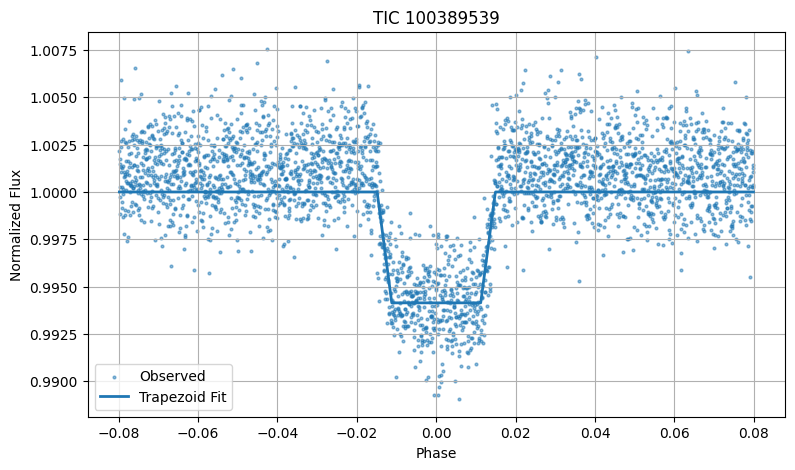

In [ ]:
# ==========================================================
# VALIDATION PLOT
# ==========================================================

planet = master[
    master["Label"] == "Planet"
].iloc[0]

tic_id = int(planet["TIC_ID"])

lightcurve = pd.read_csv(

    os.path.join(

        LIGHTCURVE_FOLDER,

        f"TIC_{tic_id}.csv"

    )

)

lightcurve = lightcurve[
    lightcurve["Sector"] == planet["Best_Sector"]
]

lightcurve = lightcurve[
    lightcurve["Quality"] == 0
]

phase = phase_fold(

    lightcurve["Time"].values,

    planet["period_days"],

    planet["epoch_days"]

)

flux = lightcurve["Normalized_Flux"].values

flux_error = lightcurve["Normalized_Flux_Error"].values

order = np.argsort(phase)

phase = phase[order]

flux = flux[order]

flux_error = flux_error[order]

duration_phase = (

    planet["duration_days"]

    / planet["period_days"]

)

mask = np.abs(phase) <= 3 * duration_phase

phase = phase[mask]

flux = flux[mask]

flux_error = flux_error[mask]

fit_result = fit_trapezoid(

    phase,

    flux,

    flux_error,

    planet["period_days"],

    planet["duration_days"]

)

features = extract_features(

    fit_result,

    phase,

    flux,

    flux_error,

    planet["period_days"]

)

plt.figure(figsize=(9,5))

plt.scatter(

    phase,

    flux,

    s=4,

    alpha=0.5,

    label="Observed"

)

plt.plot(

    phase,

    features["model_flux"],

    linewidth=2,

    label="Trapezoid Fit"

)

plt.xlabel("Phase")

plt.ylabel("Normalized Flux")

plt.title(f"TIC {tic_id}")

plt.grid(True)

plt.legend()

plt.show()

In [ ]:
# ==========================================================
# PRODUCTION LOOP
# ==========================================================

print("=" * 60)
print("TRANSIT CHARACTERIZATION STARTED")
print("=" * 60)

successful = 0
failed = 0

overall_start = time.perf_counter()

for _, row in tqdm(master.iterrows(), total=len(master)):

    tic_id = int(row["TIC_ID"])

    if tic_id in processed:
        continue

    start = time.perf_counter()

    try:

        result = process_star(row)

        # --------------------------------------------------
        # Save Features
        # --------------------------------------------------

        pd.DataFrame([{

            "TIC_ID": result["TIC_ID"],

            "depth_ppm": result["depth_ppm"],

            "T_tot_hours": result["T_tot_hours"],

            "T_in_hours": result["T_in_hours"],

            "duration_phase": result["duration_phase"],

            "ingress_phase": result["ingress_phase"],

            "red_chi2": result["red_chi2"],

            "rms_resid": result["rms_resid"]

        }]).to_csv(

            FEATURE_FILE,

            mode="a",

            header=False,

            index=False

        )

        runtime = round(

            time.perf_counter() - start,

            3

        )

        # --------------------------------------------------
        # Save Log
        # --------------------------------------------------

        pd.DataFrame([{

            "TIC_ID": tic_id,

            "Status": "SUCCESS",

            "Runtime_Seconds": runtime

        }]).to_csv(

            LOG_FILE,

            mode="a",

            header=False,

            index=False

        )

        processed.add(tic_id)

        successful += 1

    except Exception as error:

        runtime = round(

            time.perf_counter() - start,

            3

        )

        print(f"\nFailed TIC {tic_id}")

        print(type(error).__name__)

        print(error)

        pd.DataFrame([{

            "TIC_ID": tic_id,

            "Status": "FAILED",

            "Runtime_Seconds": runtime

        }]).to_csv(

            LOG_FILE,

            mode="a",

            header=False,

            index=False

        )

        failed += 1

# ----------------------------------------------------------
# Summary
# ----------------------------------------------------------

elapsed = (

    time.perf_counter()

    - overall_start

) / 60

print()

print("=" * 60)

print("TRANSIT CHARACTERIZATION COMPLETE")

print("=" * 60)

print(f"Successful : {successful}")

print(f"Failed     : {failed}")

print(f"Runtime    : {elapsed:.2f} minutes")

TRANSIT CHARACTERIZATION STARTED


100%|██████████| 1172/1172 [19:51<00:00,  1.02s/it]


TRANSIT CHARACTERIZATION COMPLETE
Successful : 1172
Failed     : 0
Runtime    : 19.86 minutes


In [ ]:
# ==========================================================
# VERIFY OUTPUT
# ==========================================================

features = pd.read_csv(FEATURE_FILE)

print("=" * 60)
print("TRANSIT FEATURE SUMMARY")
print("=" * 60)

print()

print("Rows    :", len(features))

print("Columns :", len(features.columns))

print()

display(features.head())

print()

print("Missing Values")

print(features.isna().sum())

print()

print(features.describe())

TRANSIT FEATURE SUMMARY

Rows    : 1172
Columns : 8



,TIC_ID,depth_ppm,T_tot_hours,T_in_hours,duration_phase,ingress_phase,red_chi2,rms_resid
0,100100829,6966.443066,2.348209,0.523077,0.103831,0.023129,1.294422,0.006112
1,1001477809,1659.900328,4.239923,0.203342,0.023072,0.001107,0.946671,0.003261
2,100389539,5855.195047,3.059378,0.379115,0.029782,0.003691,1.260850,0.002054
3,10048801,1001.794239,4.282757,1.068869,0.048227,0.012036,1.804031,0.000583
4,100589632,1818.380793,2.197297,0.704832,0.023197,0.007441,0.946925,0.001957



Missing Values
TIC_ID            0
depth_ppm         0
T_tot_hours       0
T_in_hours        0
duration_phase    0
ingress_phase     0
red_chi2          0
rms_resid         0
dtype: int64

             TIC_ID       depth_ppm  T_tot_hours   T_in_hours  duration_phase  \
count  1.172000e+03     1172.000000  1172.000000  1172.000000     1172.000000   
mean   2.332153e+08    48567.235518     3.998868     1.026033        0.086481   
std    1.591498e+08   108050.587125     2.484729     0.770704        0.112268   
min    7.375460e+05       40.874534     0.489986     0.039600        0.002503   
25%    1.229387e+08     2046.822309     2.256883     0.441896        0.021980   
50%    2.302209e+08     6732.400900     3.337418     0.792000        0.039057   
75%    3.408830e+08    30037.788794     5.001565     1.339188        0.096830   
max    1.965257e+09  1000000.000000    11.952000     2.988000        0.679299   

       ingress_phase       red_chi2    rms_resid  
count    1172.000000    1172.

In [ ]:
# ==========================================================
# QUALITY CONTROL
# ==========================================================

print(features.nlargest(
    10,
    "red_chi2"
)[[
    "TIC_ID",
    "depth_ppm",
    "red_chi2",
    "rms_resid"
]])

          TIC_ID      depth_ppm       red_chi2  rms_resid
921    406758816  557046.938769  217333.506349   0.119678
461    254003502   88398.848641  179314.808980   0.033850
172    148158540  339770.936322  173777.490868   0.051040
34     115105140  174725.832450  172273.411233   0.102009
301   1883519478  676605.261433  115483.018521   0.083060
502    266769522  308747.969754  103836.755314   0.096928
681     31134762  349306.262524   77247.130841   0.065142
1041   465088681    8536.144145   74737.853282   0.005855
391    229804573  148448.351826   70672.022670   0.031741
184    149861542  179425.453227   65812.961690   0.031548


In [ ]:
print(features.nlargest(
    10,
    "rms_resid"
)[[
    "TIC_ID",
    "depth_ppm",
    "red_chi2",
    "rms_resid"
]])

         TIC_ID       depth_ppm      red_chi2  rms_resid
315   193545440  1000000.000000  15800.773762   1.028341
529   271424111    12260.044871    159.291782   0.898636
722   329709756  1000000.000000    134.048688   0.440606
846    37817410   724649.661778  31932.835578   0.154588
1091   63972440   684011.578885   2263.183579   0.152822
741   340704073   297745.291713   2739.111648   0.150550
220   159939533   304058.272869   2000.884264   0.141916
370   219843981   282841.425504   9362.411401   0.135742
341   202295392   350609.950427  16505.896375   0.132146
117   138359318   109463.575054      0.954375   0.130328


In [ ]:
features["red_chi2"].quantile(

    [0.90,0.95,0.99,0.995,0.999]

)

,red_chi2
0.900,1250.899585
0.950,4416.854948
0.990,46401.071914
0.995,81102.626389
0.999,178367.927583


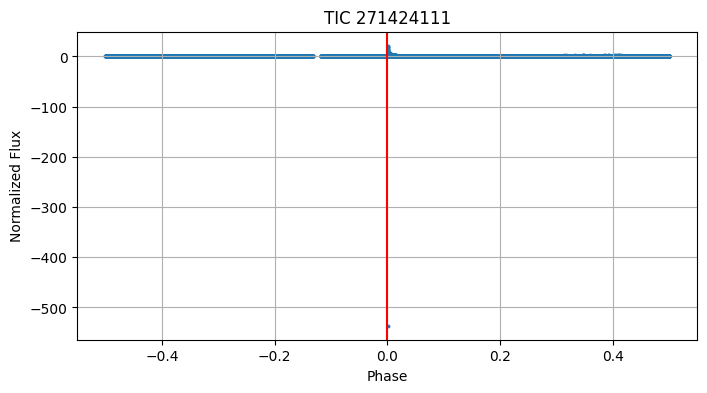

In [ ]:
# ==========================================================
# INSPECT TIC 271424111
# ==========================================================

tic = 271424111

row = master[master["TIC_ID"] == tic].iloc[0]

lc = pd.read_csv(
    os.path.join(
        LIGHTCURVE_FOLDER,
        f"TIC_{tic}.csv"
    )
)

lc = lc[
    (lc["Sector"] == row["Best_Sector"]) &
    (lc["Quality"] == 0)
].copy()

phase = phase_fold(

    lc["Time"].values,

    row["period_days"],

    row["epoch_days"]

)

flux = lc["Normalized_Flux"].values

order = np.argsort(phase)

phase = phase[order]

flux = flux[order]

plt.figure(figsize=(8,4))

plt.scatter(
    phase,
    flux,
    s=3
)

plt.axvline(0,color="red")

plt.title(f"TIC {tic}")

plt.xlabel("Phase")

plt.ylabel("Normalized Flux")

plt.grid(True)

plt.show()

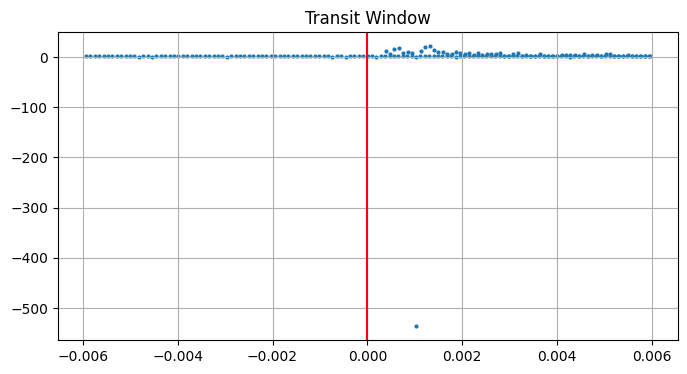

In [ ]:
duration_phase = row["duration_days"] / row["period_days"]

mask = np.abs(phase) <= 3 * duration_phase

plt.figure(figsize=(8,4))

plt.scatter(

    phase[mask],

    flux[mask],

    s=4

)

plt.axvline(0,color="red")

plt.grid(True)

plt.title("Transit Window")

plt.show()